# Audio features — STFT, Mel, Fbank
Dataset: atikuwu/karakalpak-speech-corpus

In [1]:
%pip install silero-vad

  Using cached silero_vad-6.2.3-py3-none-any.whl.metadata (11 kB)
Using cached silero_vad-6.2.3-py3-none-any.whl (11.3 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
import torch
from silero_vad import load_silero_vad

print(sys.executable)          # <-- loyiha virtual muhitidagi python bo'lishi kerak
print(torch.__version__)       # <-- 2.14.1 chiqishi kerak
vad_model = load_silero_vad()  # <-- xatosiz yuklansa, hammasi tayyor
print("Silero OK")

<python>\python.exe
2.11.0+cpu
Silero OK


In [3]:
import io
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from datasets import load_dataset, Audio as HFAudio

ds = load_dataset("atikuwu/karakalpak-speech-corpus", cache_dir="../hf_cache")

ds = ds.cast_column("audio", HFAudio(decode=False))
ds

<python>\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['id', 'audio', 'text', 'raw_text'],
        num_rows: 19554
    })
    validation: Dataset({
        features: ['id', 'audio', 'text', 'raw_text'],
        num_rows: 1074
    })
    test: Dataset({
        features: ['id', 'audio', 'text', 'raw_text'],
        num_rows: 1074
    })
})

In [4]:
# 1

SR = 16000
N_FFT = 400
HOP = 160
N_MELS = 80

print("Kadr uzunligi:", N_FFT / SR * 1000, "ms")
print("Kadr qadami  :", HOP / SR * 1000, "ms")

Kadr uzunligi: 25.0 ms
Kadr qadami  : 10.0 ms


In [5]:
# 2

sample = ds["train"][0]
wav,  sr_orig = sf.read(io.BytesIO(sample["audio"]["bytes"]), dtype="float32")
wav16 = librosa.resample(wav, orig_sr=sr_orig, target_sr=SR)    

print("Matn        :", sample["text"][:80], "...")
print("Asl SR      :", sr_orig)
print("Yangi SR    :", SR)
print("Namunalar   :", len(wav16))
print("Davomiylik  :", round(len(wav16) / SR, 2), "s")

Matn        : Isbilermenlik subektleri ushın xabardar etiw tártibi engizilip, artıqsha ruqsat  ...
Asl SR      : 48000
Yangi SR    : 16000
Namunalar   : 233816
Davomiylik  : 14.61 s


In [6]:
# 3

stft = librosa.stft(
    wav16,
    n_fft=N_FFT,
    hop_length=HOP,
    win_length=N_FFT,
    window="hann",
)

print("STFT shakli: ", stft.shape)
print("Misol      : ", stft[10, 100])

STFT shakli:  (201, 1462)
Misol      :  (-0.59454596+1.7037269j)


In [7]:
# 4

magnituda = np.abs(stft)
power = magnituda ** 2

print("Eng kichik power:", power.min())
print("Eng katta power :", power.max())

power_db = librosa.power_to_db(power, ref=np.max)       
#ref=np.max  -> eng baland nuqta 0 dB bo'ladi, qolganlari manfiy (-10, -40, -80 dB...)

print("dB oralig'i:", power_db.min(), "___", power_db.max())

Eng kichik power: 0.0
Eng katta power : 550.9622
dB oralig'i: -80.0 ___ 0.0


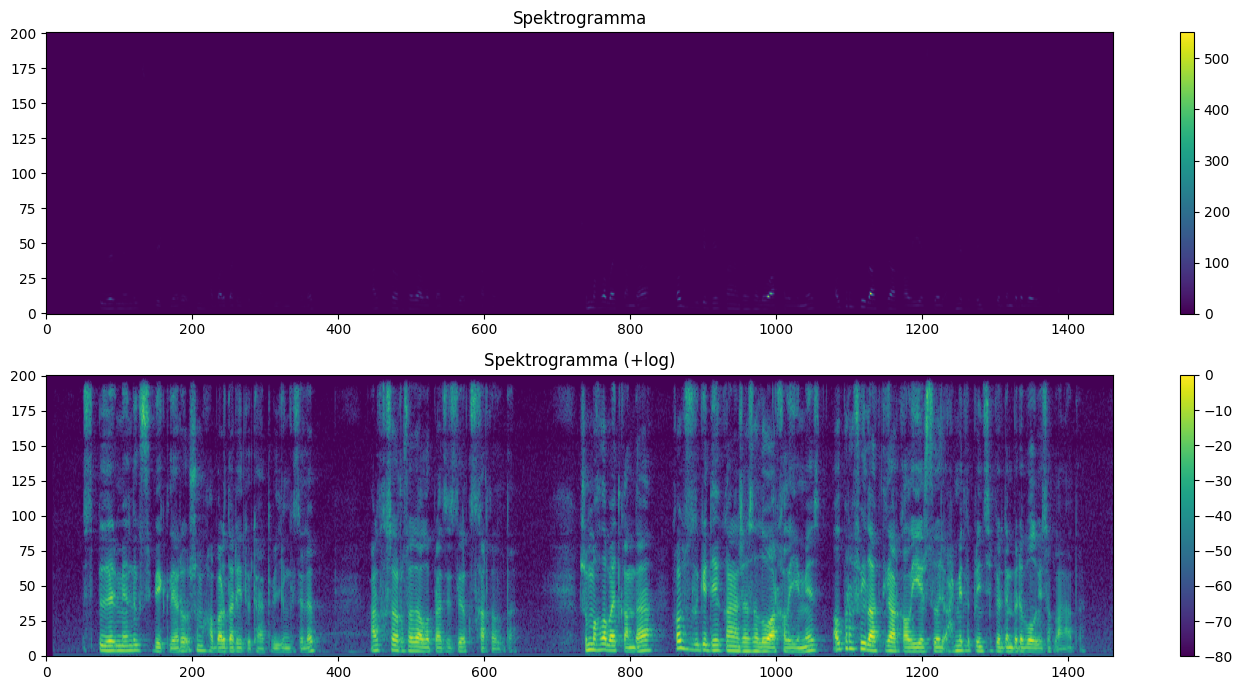

In [8]:
# 5

plt.figure(figsize=(14, 7))

# 1. Spektrogramma (log'siz)
plt.subplot(2, 1, 1)
plt.imshow(power, origin="lower", aspect="auto")
plt.title("Spektrogramma")
plt.colorbar()

# 2. Spektrogramma (log bilan, dB)
plt.subplot(2, 1, 2)
plt.imshow(power_db, origin="lower", aspect="auto")
plt.title("Spektrogramma (+log)")
plt.colorbar()

plt.tight_layout()
plt.show()

Mel filtrlar shakli:  (80, 201)


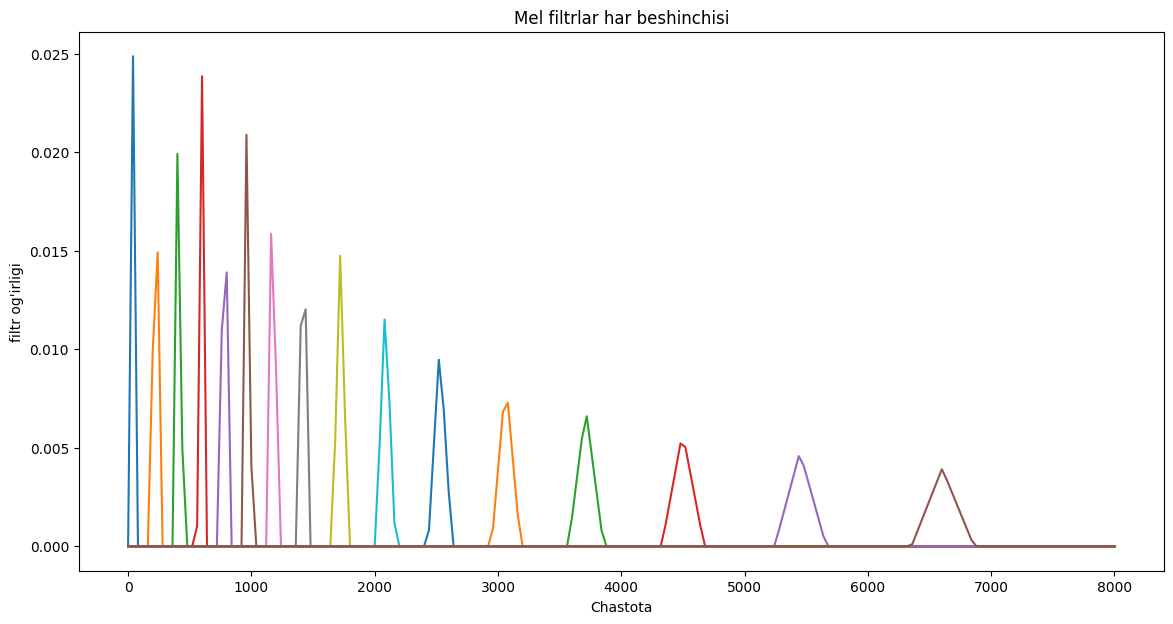

In [9]:
# 6

mel_fb = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS)
print("Mel filtrlar shakli: ", mel_fb.shape)

freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)

plt.figure(figsize=(14, 7))
for i in range(0, N_MELS, 5):
    plt.plot(freqs, mel_fb[i])

plt.xlabel("Chastota")
plt.ylabel("filtr og'irligi")
plt.title("Mel filtrlar har beshinchisi")
plt.show()

In [10]:
# 7

mel = mel_fb @ power
print("Mel shakli:", mel.shape)

fbank = librosa.power_to_db(mel, ref=np.max)
print("Fbank shakli:", fbank.shape)

Mel shakli: (80, 1462)
Fbank shakli: (80, 1462)


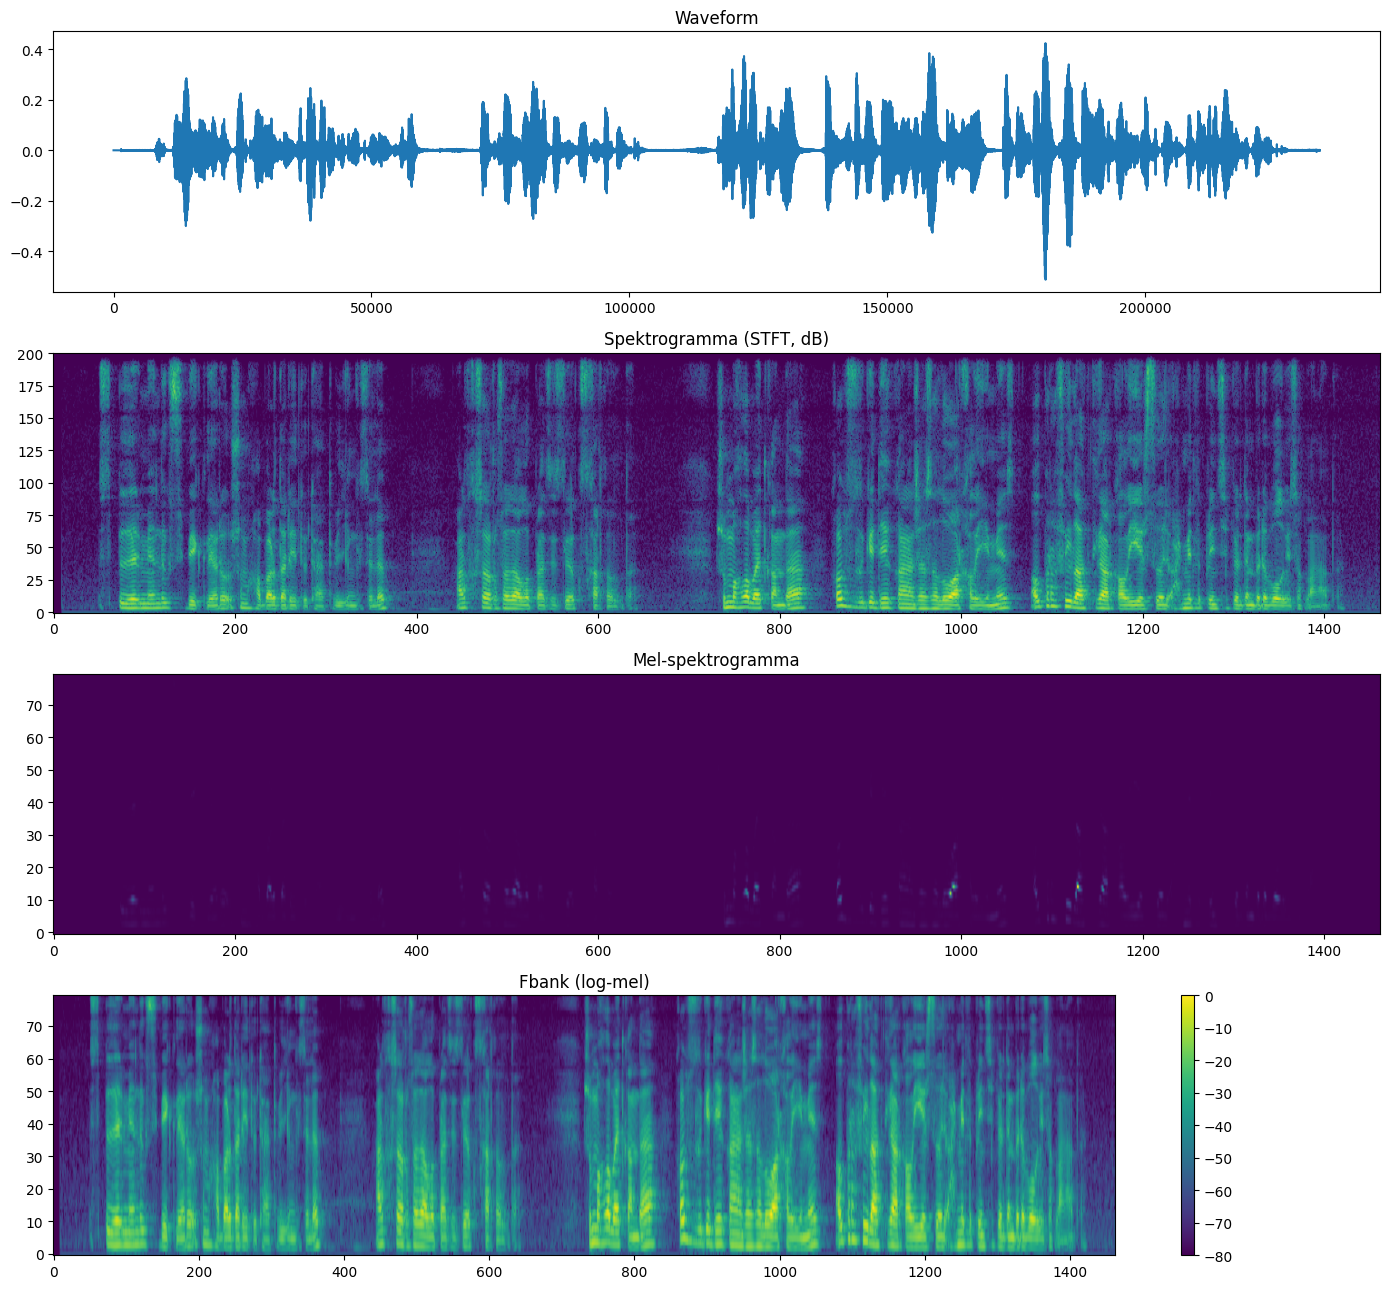

In [11]:
# 8

plt.figure(figsize=(14, 13))

# 1. Waveform
plt.subplot(4, 1, 1)
plt.plot(wav16)
plt.title("Waveform")

# 2. Spektrogramma
plt.subplot(4, 1, 2)
plt.imshow(power_db, origin="lower", aspect="auto")
plt.title("Spektrogramma (STFT, dB)")

# 3. Mel-spektrogramma
plt.subplot(4, 1, 3)
plt.imshow(mel, origin="lower", aspect="auto")
plt.title("Mel-spektrogramma")

# 4. Fbank
plt.subplot(4, 1, 4)
plt.imshow(fbank, origin="lower", aspect="auto")
plt.title("Fbank (log-mel)")
plt.colorbar()

plt.tight_layout()
plt.show()

# VAD (Voice Activity Detection) — Silero VAD
Audio da ovoz bor yoki yo'qligini tekshiramiz.

Avval energiyaga asoslangan VAD ishlatilgan edi (kadr balandligi > chegara → nutq).
U kuchli shovqinda adashdi (validation #759: nutq butun audio davomida bor, lekin nutq ulushi 18.4% chiqdi).
Endi **Silero VAD** ishlatamiz: bu neyron tarmoq, u balandlikka emas, ovoz **inson nutqiga o'xshaydimi** — shunga qaraydi.

In [12]:
# 0

# Bir marta o'rnatish (terminalda):  pip install silero-vad
import torch
from silero_vad import load_silero_vad, get_speech_timestamps

# Silero VAD modelini yuklaymiz (bir marta)
vad_model = load_silero_vad()


def silero_vad_kadrlar(audio, kadrlar_soni):
    # Silero float32 kutadi (shovqin qo'shilgan audio float64 bo'lib qolishi mumkin)
    audio = audio.astype(np.float32)

    # 1. Silero nutq bo'laklarini topadi: [{"start": 8160, "end": 52000}, ...]
    #    start va end - NAMUNA (sample) raqamlari, soniya emas
    segmentlar = get_speech_timestamps(
        torch.from_numpy(audio),
        vad_model,
        sampling_rate=SR,
        threshold=0.5,               # nutq ehtimoli 0.5 dan katta bo'lsa -> nutq
        min_silence_duration_ms=100, # 0.1 s dan qisqa pauza nutqni bo'lmaydi
        speech_pad_ms=30,            # nutq atrofida 30 ms zaxira
    )

    # 2. Boshida hamma kadrlar "jimlik" (False)
    is_speech = np.zeros(kadrlar_soni, dtype=bool)

    # 3. Har bir nutq bo'lagini kadrlarga aylantiramiz: 1 kadr = HOP (160) namuna = 10 ms
    for seg in segmentlar:
        bosh_kadr = seg["start"] // HOP
        oxir_kadr = seg["end"] // HOP
        for i in range(bosh_kadr, oxir_kadr + 1):
            if i < kadrlar_soni:
                is_speech[i] = True

    return is_speech

In [13]:
# 1

# Har bir bo'lak (kadr) qanchalik baland ekanini o'lchaymiz
rms = librosa.feature.rms(y=wav16, frame_length=400, hop_length=160)
rms = rms[0]

# Detsibelga o'tkazamiz (eng baland joy = 0 dB)
rms_db = librosa.amplitude_to_db(rms, ref=np.max)

print("Kadrlar soni:", len(rms_db))

Kadrlar soni: 1462


In [14]:
# 2

# Silero VAD: har bir kadr nutqmi (True) yoki jimlikmi (False)
is_speech = silero_vad_kadrlar(wav16, len(rms_db))

nutq_kadrlar = is_speech.sum()
jami_kadrlar = len(is_speech)

print("Nutq ulushi     :", round(nutq_kadrlar / jami_kadrlar * 100, 1), "%")

Nutq ulushi     : 84.1 %


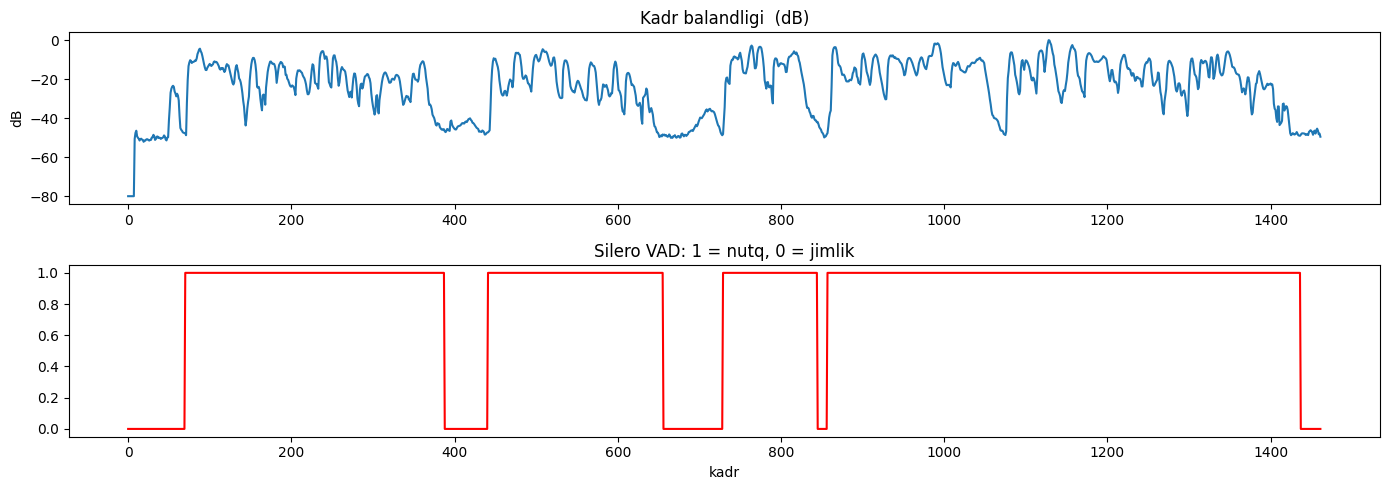

In [15]:
# 3

plt.figure(figsize=(14, 5))

# Kadr balandligi
plt.subplot(2, 1, 1)
plt.plot(rms_db)
plt.title("Kadr balandligi  (dB)")
plt.ylabel("dB")

# Silero VAD qarori: 1 = nutq, 0 = jimlik
plt.subplot(2, 1, 2)
plt.plot(is_speech, color="red")
plt.title("Silero VAD: 1 = nutq, 0 = jimlik")
plt.xlabel("kadr")

plt.tight_layout()
plt.show()

In [16]:
# 4

# Birinchi nutq kadrini topamiz
birinchi = 0
for i in range(len(is_speech)):
    if is_speech[i]:
        birinchi = i
        break

# Oxirgi nutq kadrini topamiz
oxirgi = 0
for i in range(len(is_speech)):
    if is_speech[i]:
        oxirgi = i

# 1 kadr = 10 ms = 0.01 soniya
bosh_pauza = birinchi * 0.01
oxir_pauza = (len(is_speech) - 1 - oxirgi) * 0.01

print("Boshidagi jimlik:", round(bosh_pauza, 2), "s")
print("Oxiridagi jimlik:", round(oxir_pauza, 2), "s")

Boshidagi jimlik: 0.7 s
Oxiridagi jimlik: 0.25 s


# SNR (Signal-to-Noise Ratio)
G'oya: nutq bor kadrlarning o'rtacha kuchini va jimlik kadrlarining o'rtacha kuchini (ya'ni fon shovqinini) hisoblaymiz. Keyin ularni solishtiramiz.

In [17]:
# 1

nutq = rms[is_speech]
shovqin = rms[is_speech == False]

nutq_kuchi = np.mean(nutq ** 2)
shovqin_kuchi = np.mean(shovqin ** 2)

# SNR formulasi (dB)
snr = 10 * np.log10(nutq_kuchi / shovqin_kuchi)

print("SNR:", round(snr, 1), "dB")

SNR: 25.7 dB


In [18]:
# 2

def snr_hisob(audio):
    # 1 Har bir kadr balandligi
    rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)
    rms = rms[0]

    # 2 VAD nutq qayerda (Silero)
    is_speech = silero_vad_kadrlar(audio, len(rms))

    # 3 Nutq va Shovqin kadrlar
    nutq = rms[is_speech]
    shovqin = rms[is_speech == False]

    # Agar nutq yoki jimlik bo'lmasa SNR ni hisoblab bo'lmaydi
    if len(nutq) == 0 or len(shovqin) == 0:
        return None

    # 4 SNR
    nutq_kuchi = np.mean(nutq ** 2)
    shovqin_kuchi = np.mean(shovqin ** 2)
    snr = 10 * np.log10(nutq_kuchi / shovqin_kuchi)
    return snr

In [19]:
# 3

# Har safar bir xil natija chiqishi uchun
np.random.seed(0)

# Toza audio
print("Toza audio SNR       :", round(snr_hisob(wav16), 1), "dB")

# Ozgina shovqin qo'shamiz
shovqinli_1 = wav16 + np.random.randn(len(wav16)) * 0.02
print("Ozgina shovqin SNR   :", round(snr_hisob(shovqinli_1), 1), "dB")

# Ko'p shovqin qo'shamiz
shovqinli_2 = wav16 + np.random.randn(len(wav16)) * 0.05
print("Ko'p shovqin SNR     :", round(snr_hisob(shovqinli_2), 1), "dB")

Toza audio SNR       : 25.7 dB
Ozgina shovqin SNR   : 8.3 dB
Ko'p shovqin SNR     : 2.8 dB


In [20]:
print("Toza:")
display(Audio(wav16, rate=SR))

print("Ko'p shovqinli:")
display(Audio(shovqinli_2, rate=SR))

Toza:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


Ko'p shovqinli:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


# Dataset bo'yicha SNR va nutq ulushi

In [21]:
def audio_tahlil(audio):
    rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)
    rms = rms[0]

    # Audioning eng baland joyi (absolyut, dB).
    eng_baland_db = 20 * np.log10(rms.max() + 1e-10)

    # VAD (Silero)
    is_speech = silero_vad_kadrlar(audio, len(rms))

    # Nutq ulushi
    nutq_ulushi = is_speech.sum() / len(is_speech) * 100

    nutq = rms[is_speech]
    shovqin = rms[is_speech == False]

    if len(nutq) == 0 or len(shovqin) == 0:
        return None, nutq_ulushi, eng_baland_db

    nutq_kuchi = np.mean(nutq ** 2)
    shovqin_kuchi = np.mean(shovqin ** 2)
    snr = 10 * np.log10(nutq_kuchi / shovqin_kuchi)

    return snr, nutq_ulushi, eng_baland_db


def kategoriya_top(snr, eng_baland_db):
    if eng_baland_db < -45:
        return "jim"
    if snr is None:
        return "shovqinli"
    if snr < 15:
        return "shovqinli"
    return "toza"

In [22]:
from tqdm.auto import tqdm

natijalar = []

for split in ["train", "validation", "test"]:
    for i in tqdm(range(len(ds[split])), desc=split):
        ex = ds[split][i]

        # Audio ni o'qib, 16 kHz ga o'tkazamiz
        wav, sr_orig = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
        audio = librosa.resample(wav, orig_sr=sr_orig, target_sr=SR)

        # SNR, nutq ulushi va kategoriya
        snr, nutq_ulushi, eng_baland_db = audio_tahlil(audio)
        kategoriya = kategoriya_top(snr, eng_baland_db)

        natijalar.append({
            "split": split,
            "idx": i,
            "davomiylik": len(audio) / SR,
            "snr": snr,
            "nutq_ulushi": nutq_ulushi,
            "eng_baland_db": eng_baland_db,
            "kategoriya": kategoriya,
        })

df_f = pd.DataFrame(natijalar)
df_f.to_csv("audio_features_silero.csv", index=False)

print("Jami:", len(df_f))
df_f.head()

train:  53%|█████▎    | 10394/19554 [31:22<23:34,  6.48it/s] <ipykernel>\1542799617.py:22: RuntimeWarning: divide by zero encountered in scalar divide
  snr = 10 * np.log10(nutq_kuchi / shovqin_kuchi)
test: 100%|██████████| 1074/1074 [28:21<00:00,  1.58s/it]


Jami: 21702


,split,idx,davomiylik,snr,nutq_ulushi,eng_baland_db,kategoriya
0,train,0,14.6135,25.654499,84.062927,-13.982258,toza
1,train,1,15.4400,25.811787,93.203883,-18.738920,toza
2,train,2,17.7735,45.608143,99.493813,-16.689869,toza
3,train,3,20.2735,35.947281,91.124260,-9.429944,toza
4,train,4,14.7735,34.546608,98.714479,-25.407837,toza


In [23]:
print(df_f[["snr", "nutq_ulushi"]].describe().round(1))

           snr  nutq_ulushi
count  21480.0      21702.0
mean       inf         94.1
std        NaN          6.2
min      -12.0          0.0
25%       20.7         92.4
50%       28.7         95.6
75%       35.4         97.7
max        inf        100.0


<python>\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


In [30]:
bad = ~np.isfinite(df_f["snr"])
print("inf/nan soni:", bad.sum(), "/", len(df_f))
df_f[bad].head()   # qaysi audiolar ekanini ko'rib, 2-3 tasini tinglang

inf/nan soni: 230 / 21702


,split,idx,davomiylik,snr,nutq_ulushi,eng_baland_db,kategoriya
648,train,648,12.0935,NaN,100.0,-22.043713,shovqinli
909,train,909,27.3735,NaN,100.0,-19.081444,shovqinli
967,train,967,20.8535,NaN,100.0,-15.724591,shovqinli
1244,train,1244,17.0135,NaN,100.0,-20.954586,shovqinli
1315,train,1315,13.4935,NaN,100.0,-15.610260,shovqinli


In [34]:
df_f[df_f["snr"].between(80, 1e9)].sort_values("snr", ascending=False).head(10)

,split,idx,davomiylik,snr,nutq_ulushi,eng_baland_db,kategoriya
20944,test,316,13.4935,242.964630,99.777778,-22.728592,toza
12000,train,12000,22.3335,239.431381,99.865712,-18.377150,toza
18079,train,18079,12.3735,227.605362,99.273021,-18.494364,toza
2477,train,2477,14.2135,222.547852,99.789030,-16.778400,toza
11583,train,11583,11.2935,213.704529,98.584071,-9.474527,toza
5366,train,5366,14.5735,212.867569,99.794239,-17.513432,toza
16378,train,16378,14.0800,209.369476,97.303052,-16.966503,toza
1699,train,1699,24.8400,208.979202,98.470825,-19.371956,toza
13354,train,13354,17.4135,208.571014,99.827784,-26.965511,toza
15196,train,15196,19.2800,204.291656,98.030067,-20.033764,toza


In [32]:
print(df_f.loc[bad, "nutq_ulushi"].describe())
print(df_f.loc[bad, "kategoriya"].value_counts())

count    230.000000
mean      91.733032
std       27.587211
min        0.000000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.000000
Name: nutq_ulushi, dtype: float64
kategoriya
shovqinli    222
toza           8
Name: count, dtype: int64


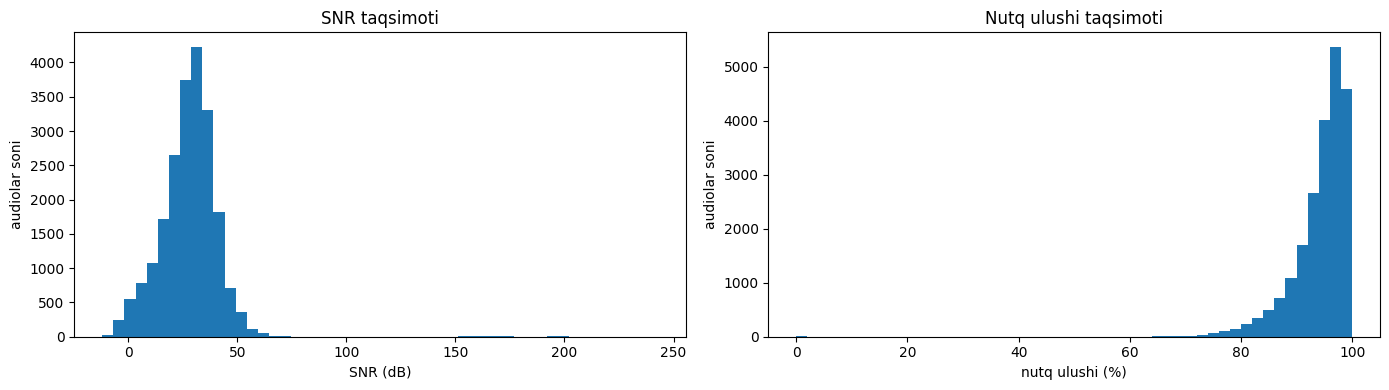

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
snr_ok = df_f.loc[~bad, "snr"]

axes[0].hist(snr_ok, bins=50)
axes[0].set_title(f"SNR taqsimoti ({bad.sum()} ta inf chiqarib tashlandi)")
axes[0].set_title("SNR taqsimoti")
axes[0].set_xlabel("SNR (dB)")
axes[0].set_ylabel("audiolar soni")

axes[1].hist(df_f["nutq_ulushi"], bins=50)
axes[1].set_title("Nutq ulushi taqsimoti")
axes[1].set_xlabel("nutq ulushi (%)")
axes[1].set_ylabel("audiolar soni")

plt.tight_layout()
plt.show()

In [35]:
print("=== Soni ===")
print(df_f["kategoriya"].value_counts())

print("\n=== Foizda ===")
print((df_f["kategoriya"].value_counts() / len(df_f) * 100).round(2))

print("\n=== Soatda ===")
print((df_f.groupby("kategoriya")["davomiylik"].sum() / 3600).round(2))

print("\n=== Split bo'yicha ===")
print(pd.crosstab(df_f["split"], df_f["kategoriya"], margins=True))

=== Soni ===
kategoriya
toza         18405
shovqinli     3297
Name: count, dtype: int64

=== Foizda ===
kategoriya
toza         84.81
shovqinli    15.19
Name: count, dtype: float64

=== Soatda ===
kategoriya
shovqinli    16.08
toza         90.84
Name: davomiylik, dtype: float64

=== Split bo'yicha ===
kategoriya  shovqinli   toza    All
split                              
test              139    935   1074
train            3018  16536  19554
validation        140    934   1074
All              3297  18405  21702


# Toza, shovqinli va jim audio spektrogrammalari

In [36]:
# 1

# Eng katta SNR -> eng toza
eng_toza = df_f.sort_values("snr", ascending=False).iloc[0]

# Eng kichik SNR -> eng shovqinli
eng_shovqinli = df_f.sort_values("snr").iloc[0]

print("Toza     :", eng_toza.to_dict())
print("Shovqinli:", eng_shovqinli.to_dict())

Toza     : {'split': 'train', 'idx': 17793, 'davomiylik': 20.0535, 'snr': inf, 'nutq_ulushi': 99.85044865403788, 'eng_baland_db': -15.51116943359375, 'kategoriya': 'toza'}
Shovqinli: {'split': 'train', 'idx': 4718, 'davomiylik': 20.84, 'snr': -11.982736587524414, 'nutq_ulushi': 95.92326139088729, 'eng_baland_db': -0.9150436520576477, 'kategoriya': 'shovqinli'}


In [37]:
# 2

def audio_ol(split, idx):
    ex = ds[split][idx]
    wav, sr_orig = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    audio = librosa.resample(wav, orig_sr=sr_orig, target_sr=SR)
    return audio, ex["text"]

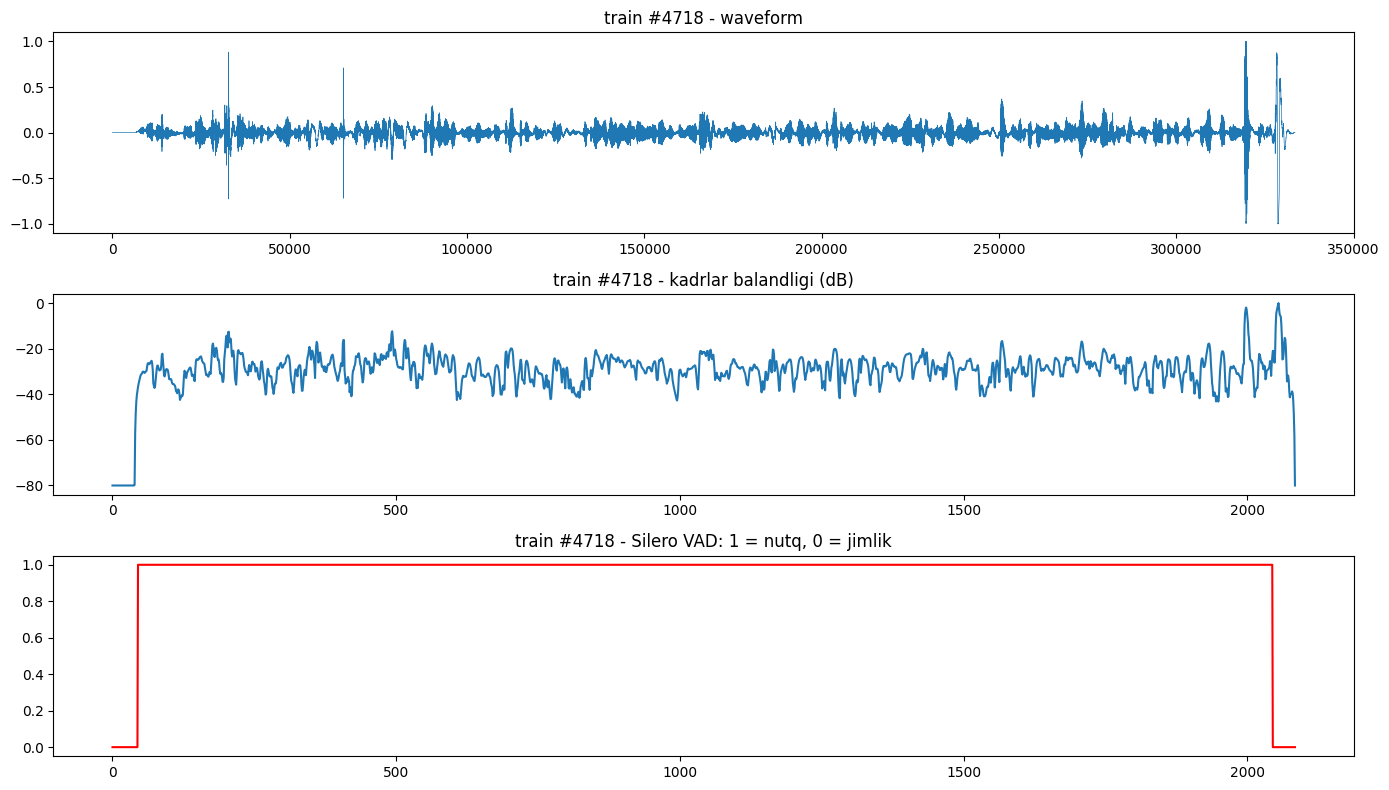

In [38]:
# 3

audio, matn = audio_ol(eng_shovqinli["split"], int(eng_shovqinli["idx"]))
nom = eng_shovqinli["split"] + " #" + str(int(eng_shovqinli["idx"]))

rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)
rms = rms[0]
rms_db = librosa.amplitude_to_db(rms, ref=np.max)

# VAD - xuddi audio_tahlil dagidek (Silero)
is_speech = silero_vad_kadrlar(audio, len(rms))

fig, axes = plt.subplots(3, 1, figsize=(14, 8))

axes[0].plot(audio, linewidth=0.5)
axes[0].set_title(nom + " - waveform")

axes[1].plot(rms_db)
axes[1].set_title(nom + " - kadrlar balandligi (dB)")

axes[2].plot(is_speech, color="red")
axes[2].set_title(nom + " - Silero VAD: 1 = nutq, 0 = jimlik")

plt.tight_layout()
plt.show()

eng shovqinli audio (Silero bilan qayta hisoblangan): ___ (SNR ___ dB, nutq ulushi ___%).

Kuzatuv: ___

## Energy VAD va Silero VAD solishtirish — validation #759
Eski usul shu audioda adashgan edi (nutq ulushi 18.4%). Ikkala VAD'ni bitta audioda yonma-yon ko'ramiz.

Energy VAD nutq ulushi: 18.4 %
Silero VAD nutq ulushi: 99.6 %


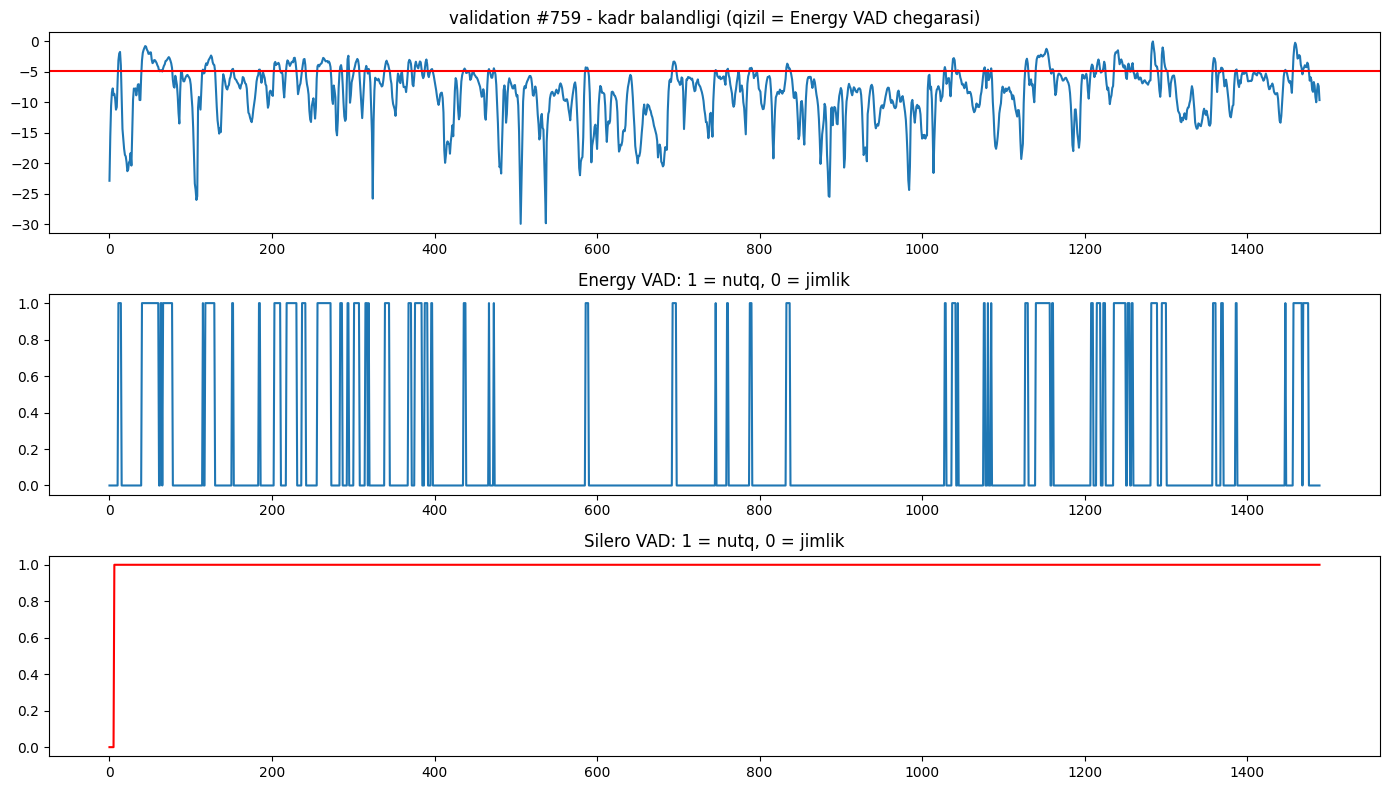

[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


In [39]:
audio, matn = audio_ol("validation", 759)

rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)
rms = rms[0]
rms_db = librosa.amplitude_to_db(rms, ref=np.max)

# Eski usul: Energy VAD
shovqin_darajasi = np.percentile(rms_db, 10)
chegara = max(-40, shovqin_darajasi + 10)
energy_speech = rms_db > chegara

# Yangi usul: Silero VAD
silero_speech = silero_vad_kadrlar(audio, len(rms))

print("Energy VAD nutq ulushi:", round(energy_speech.sum() / len(energy_speech) * 100, 1), "%")
print("Silero VAD nutq ulushi:", round(silero_speech.sum() / len(silero_speech) * 100, 1), "%")

fig, axes = plt.subplots(3, 1, figsize=(14, 8))

axes[0].plot(rms_db)
axes[0].axhline(chegara, color="red")
axes[0].set_title("validation #759 - kadr balandligi (qizil = Energy VAD chegarasi)")

axes[1].plot(energy_speech)
axes[1].set_title("Energy VAD: 1 = nutq, 0 = jimlik")

axes[2].plot(silero_speech, color="red")
axes[2].set_title("Silero VAD: 1 = nutq, 0 = jimlik")

plt.tight_layout()
plt.show()

display(Audio(audio, rate=SR, normalize=False))

In [40]:
# 4

# Toza va shovqinli - datasetdan
toza_audio, toza_matn = audio_ol(eng_toza["split"], int(eng_toza["idx"]))
shovqinli_audio, shovqinli_matn = audio_ol(eng_shovqinli["split"], int(eng_shovqinli["idx"]))

print("Toza matn     :", toza_matn)
print("Shovqinli matn:", shovqinli_matn)

# Jim - o'zimiz yaratamiz: 5 soniyalik "xona jimligi" (juda past shovqin)
jim_audio = np.random.randn(SR * 5) * 0.0005
jim_audio = jim_audio.astype(np.float32)

print("Jim audio SNR :", snr_hisob(jim_audio))

Toza matn     : Ózbekstan Respublikası ǵárezsizliginiń otız tórt jıllıǵı múnásibeti menen mámleketlik xızmetkerler hám óndiris hám sociallıq-ekonomikalıq tarawlar xızmetkerlerinen bir toparın sıylıqlaw haqqında Ózbekstan Respublikası Prezidentiniń Pármanı Mámleketimizde keń kólemli reformalardı tabıslı ámelge asırıw, elimizdiń ekonomikalıq rawajlanıwı hám xalqımızdıń abadanlıǵın támiyinlew,
Shovqinli matn: Sonlıqtan, joybardı jetilistiriw dawamında bunday qosımshalardıń kirip keliwi hám paydalanılıwın qadaǵalaw máselelerinede itibar qaratıwımız kerek. Qızǵın dodalawlar dawamında veterinariya xızmetleriniń sapasın arttırıw, veterinariya-sanitariyalıq qáwipsizlikti támiyinlewde nızam joybarınıń áhmiyeti atap ótilip, qollap-quwatlandı.
Jim audio SNR : None


In [42]:
# normalize=False - ovozni avtomatik balandlatmasin.
# Aks holda jim audio ham baland "shshsh" bo'lib eshitiladi.
print("Toza:")
display(Audio(toza_audio, rate=SR, normalize=False))

print("Shovqinli:")
display(Audio(shovqinli_audio, rate=SR))

print("Jim:")
display(Audio(jim_audio, rate=SR, normalize=False))

Toza:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


Shovqinli:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


Jim:


[audio pleyer — repoda hajmni kamaytirish uchun olib tashlangan]


<ipykernel>\3866170572.py:22: RuntimeWarning: divide by zero encountered in scalar divide
  snr = 10 * np.log10(nutq_kuchi / shovqin_kuchi)


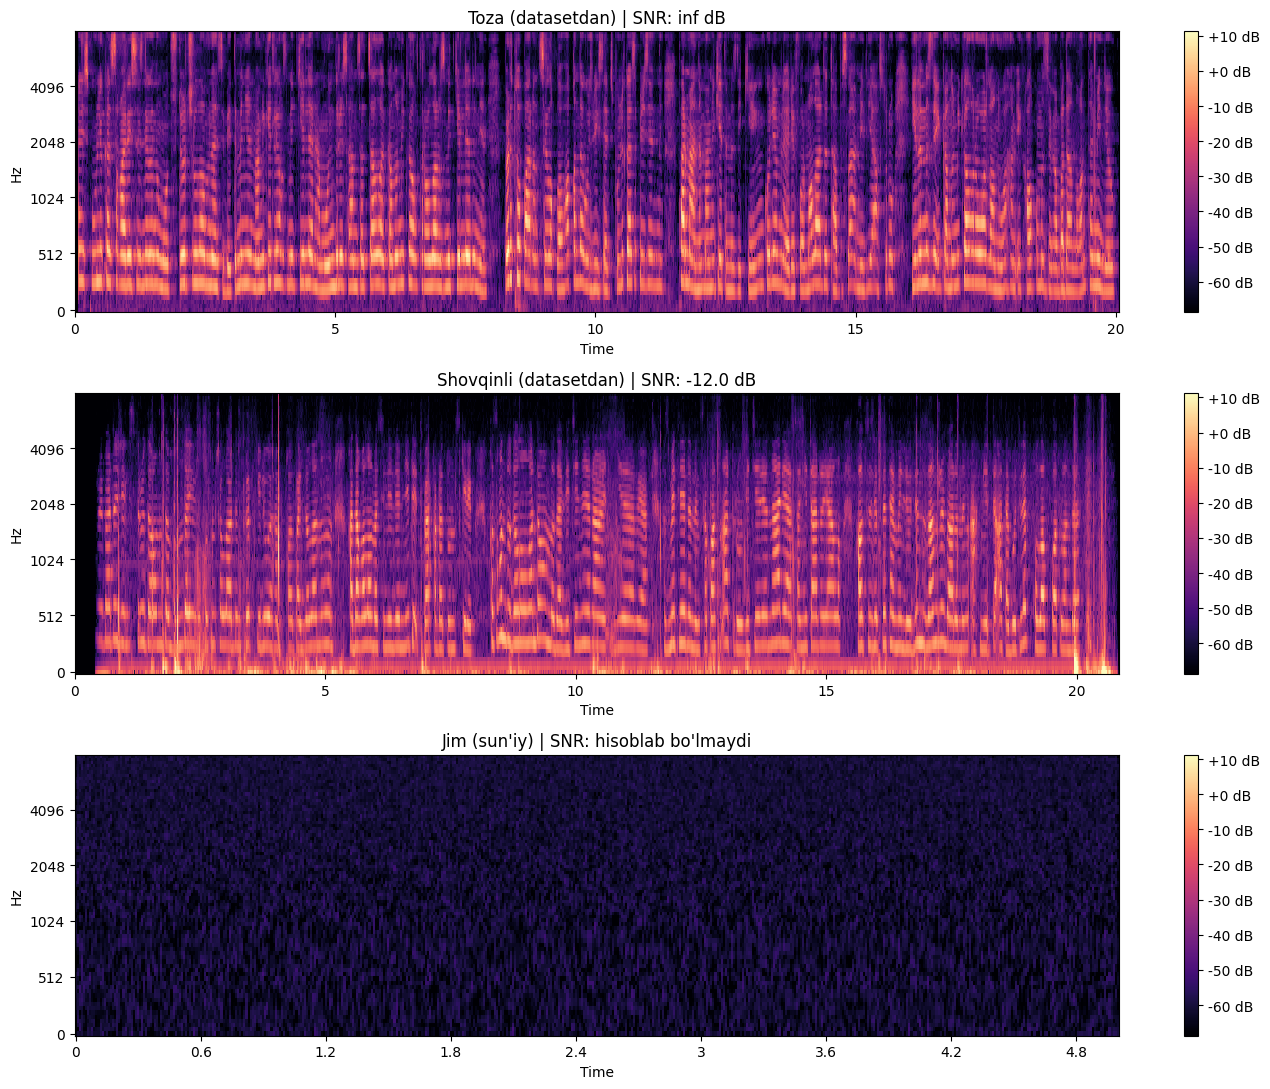

In [43]:
audiolar = [
    ("Toza (datasetdan)", toza_audio),
    ("Shovqinli (datasetdan)", shovqinli_audio),
    ("Jim (sun'iy)", jim_audio),
]

# 1. Uchalasining fbank'ini hisoblaymiz (umumiy shkala: ref=1.0)
fbanklar = []
for nom, audio in audiolar:
    mel = librosa.feature.melspectrogram(y=audio, sr=SR, n_fft=400, hop_length=160, n_mels=80)
    fbank = librosa.power_to_db(mel, ref=1.0, top_db=None)
    fbanklar.append(fbank)

# 2. Rang shkalasi: toza audioning eng baland nuqtasidan 80 dB pastgacha
eng_katta = fbanklar[0].max()

# 3. Chizamiz
fig, axes = plt.subplots(3, 1, figsize=(14, 11))

for k in range(3):
    nom = audiolar[k][0]
    audio = audiolar[k][1]

    img = librosa.display.specshow(fbanklar[k], sr=SR, hop_length=160,
                                   x_axis="time", y_axis="mel", ax=axes[k],
                                   vmin=eng_katta - 80, vmax=eng_katta)

    snr = snr_hisob(audio)
    if snr is None:
        axes[k].set_title(nom + " | SNR: hisoblab bo'lmaydi")
    else:
        axes[k].set_title(nom + " | SNR: " + str(round(snr, 1)) + " dB")
    fig.colorbar(img, ax=axes[k], format="%+2.0f dB")

plt.tight_layout()
plt.savefig("toza_shovqinli_jim_silero.png")
plt.show()

In [44]:
kam = (df_f["snr"] < 10).sum()
print("SNR < 10 dB:", kam, "ta,", round(kam / len(df_f) * 100, 1), "%")

SNR < 10 dB: 1889 ta, 8.7 %


## Xulosa

### Nima qilindi
1. **STFT → Mel → Fbank** zanjiri bitta audioda qadamma-qadam qurildi.
   Log shkala bo'lmasa nutq deyarli ko'rinmasligi, mel filtrlar esa past
   chastotalarni batafsilroq saqlashi ko'rsatildi.
   Fbank o'lchami: 80 × T (1 soniya ≈ 100 kadr).
2. **VAD**: avval energiyaga asoslangan (kadr RMS, dB, chegara = shovqin darajasi + 10 dB).
   U kuchli shovqinda adashgani uchun **Silero VAD** (neyron tarmoq) bilan almashtirildi.
   Silero nutq bo'laklarini beradi, ular 10 ms'lik kadrlarga aylantiriladi.
3. **SNR**: nutq va shovqin kadrlarining o'rtacha kuchi nisbati (dB).
   Nutq/shovqin kadrlarini endi Silero VAD ajratadi.
4. **Dataset tahlili**: barcha 21 702 ta audio (train + validation + test, ~107 soat).

### Energy VAD va Silero VAD natijalari

| Ko'rsatkich | Energy VAD (eski) | Silero VAD (yangi) |
|---|---|---|
| SNR mediana | 23.2 dB | ___ |
| Nutq ulushi mediana | 75.9% | ___ |
| "shovqinli" (SNR < 15 dB) | 1757 ta (8.1%, ~8 soat) | ___ |
| SNR < 10 dB | 219 ta (1.0%) | ___ |
| validation #759 nutq ulushi | 18.4% | ___ |
| Eng toza audio | train #4242, 46.9 dB | ___ |
| Eng shovqinli audio | validation #759, 4.9 dB | ___ |

### Topilmalar
- ___ (Silero natijalari bo'yicha yozing)
- Datasetda haqiqiy jim audio topilmadi ("jim" kategoriyasi 0 ta), shuning uchun
  jim audio sun'iy yaratildi (past darajadagi oq shovqin).

### Usul cheklovlari
- Energiyaga asoslangan VAD kuchli shovqinda adashdi: validation #759 da nutq
  butun audio davomida bor, lekin nutq ulushi 18.4% deb chiqdi. Shu sababli Silero VAD'ga o'tildi.
- Silero VAD sekinroq: butun datasetni qayta ishlash ko'proq vaqt oladi.
- ___